# Objectif 

Recherche d'une situation passive favorable à la démonstration de la méthode de localisation dans le cas library actif / event passif.

Date de création : 28/10/2026

In [2]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [3]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


# Chargement des données 

## Données de la portion pour la librairie 
Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [4]:
portion_id = 5
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath, auto_complex=True)
portion

<xarray.DataTree>
Group: /
│   Attributes:
│       portion_filepath:  /home/program/ubf_tools/real_data_analysis/acouplane/d...
├── Group: /position
│   ├── Group: /position/sn0
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2313, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 790)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 19kB 2026-02-25T09:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T09:5...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 19kB ...
│   │           atl_lat                 (atl_datetime) float64 19kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 44kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 44kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 44kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               5
│   │           section_orientation:      South/North
│   │           section_id:               0
│   │           section_label:            sn0
│   │           obs_position:             OBS position corrected using LMS inversion.
│   │           obs_position_filepath:    C:\Users\baptiste.menetrier\Desktop\devPy\phd\r...
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 2120, mmsi: 526,
│   │                                    ais_datetime: 241, src_datetime: 800)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 17kB 2026-02-25T11:...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 2kB 2026-02-25T11:1...
│   │         * src_datetime            (src_datetime) datetime64[ns] 6kB 2026-02-25T11:1...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B ...
│   │           rcv_lat                 (rcv_id) float64 56B ...
│   │           rcv_immersion           (rcv_id) int16 14B ...
│   │           atl_lon                 (atl_datetime) float64 17kB ...
│   │           atl_lat                 (atl_datetime) float64 17kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 1MB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 6kB ...
│   │           tir_vessel_lon          (src_datetime) float64 6kB ...
│   │           tir_vessel_lat          (src_datetime) float64 6kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 45kB ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 45kB ...
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 45kB ...
│   │       Attributes:
│   │           description:              Posi

## Données de positions 
Toutes les données disponibles : 

* Données AIS 
* Données de l'ATALANTE 

In [5]:
ds_pos = xr.open_dataset(ACOUPLANE_POSITIONS_NC_FPATH)
print(ds_pos)

<xarray.Dataset> Size: 525MB
Dimensions:         (rcv_id: 7, atl_datetime: 563739, mmsi: 526,
                     ais_datetime: 60447, src_datetime: 33608)
Coordinates:
  * rcv_id          (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs7' 'tlq'
  * atl_datetime    (atl_datetime) datetime64[ns] 5MB 2026-02-24 ... 2026-03-...
  * ais_datetime    (ais_datetime) datetime64[ns] 484kB 2026-02-23T23:59:50 ....
  * src_datetime    (src_datetime) datetime64[ns] 269kB 2026-02-24T20:14:06.6...
Dimensions without coordinates: mmsi
Data variables: (12/13)
    rcv_lon         (rcv_id) float64 56B ...
    rcv_lat         (rcv_id) float64 56B ...
    rcv_immersion   (rcv_id) int16 14B ...
    atl_lon         (atl_datetime) float64 5MB ...
    atl_lat         (atl_datetime) float64 5MB ...
    ais_lon         (mmsi, ais_datetime) float64 254MB ...
    ...              ...
    tir_SEGD        (src_datetime) int64 269kB ...
    tir_ECOS        (src_datetime) int64 269kB ...
    tir_src_lon     (src_date

# Étude des positions des sources passives 

## Définition d'une zone d'intérêt

On commence par définir la zone de recherche. Cette zone correspond à la zone du maillage de la librairie + un petit offset pour mieux visualiser la trajectoire des sources avant et après avoir traversé la grille. 

In [6]:
# Step 1: select AIS pos in the area of interest
lon_offset_percentage = lat_offset_percentage = 0.001

lon_min, lon_max = np.min([
    node.to_dataset().tir_src_lon.min() for _, node in portion.position.children.items()
]) * (1 - lon_offset_percentage / 2), np.max(
    [
    node.to_dataset().tir_src_lon.max() for _, node in portion.position.children.items()
]
) * (1 + lon_offset_percentage / 2)
lat_min, lat_max = np.min([
    node.to_dataset().tir_src_lat.min() for _, node in portion.position.children.items()
]) * (1 - lat_offset_percentage / 2), np.max(
    [
    node.to_dataset().tir_src_lat.max() for _, node in portion.position.children.items()
]
) * (1 + lat_offset_percentage / 2)
lon_min, lon_max, lat_min, lat_max

(np.float64(5.919009015),
 np.float64(5.965350184499999),
 np.float64(42.973826338),
 np.float64(43.07525886599999))

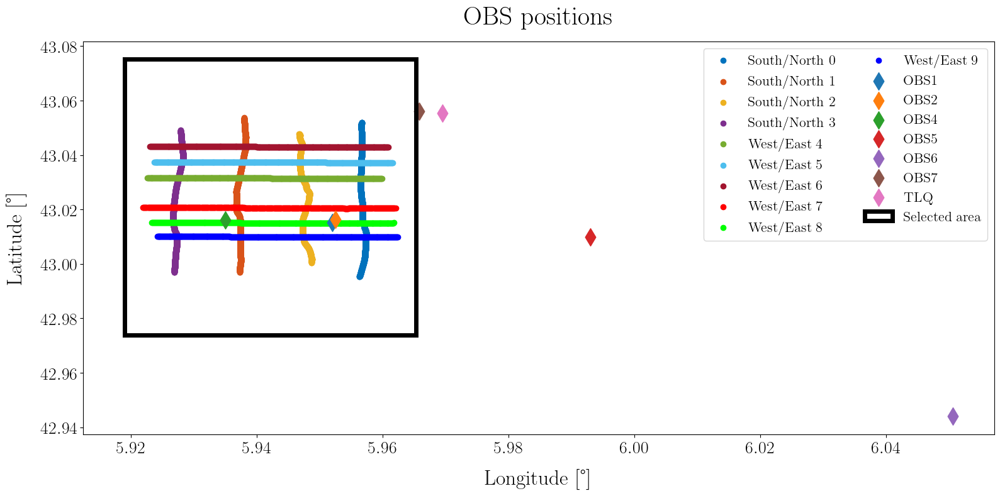

In [7]:
# Illustrate on map
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (lon_min, lat_min),
        lon_max - lon_min,
        lat_max - lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)
ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

## Position AIS 

On extrait ensuite les positions AIS qui passe dans la boite définie. 

In [8]:
ds_ais = ds_pos.copy().drop_vars(
    [v for v in list(ds_pos.variables) if v not in ["ais_lon", "ais_lat", "ais_datetime"]]
)

mask = (
    (ds_ais["ais_lon"] >= lon_min)
    & (ds_ais["ais_lon"] <= lon_max)
    & (ds_ais["ais_lat"] >= lat_min)
    & (ds_ais["ais_lat"] <= lat_max)
)

# Mask and drop coordinates that have no positions in the area
ds_ais_in_area = (
    ds_ais.where(mask).dropna("ais_datetime", how="all").dropna("mmsi", how="all")
)
# Add mmsi to ease selection
ds_ais_in_area = ds_ais_in_area.assign_coords(mmsi=np.arange(ds_ais_in_area.sizes["mmsi"]))
ds_ais_in_area

<xarray.Dataset> Size: 17MB
Dimensions:       (mmsi: 78, ais_datetime: 13204)
Coordinates:
  * mmsi          (mmsi) int64 624B 0 1 2 3 4 5 6 7 ... 70 71 72 73 74 75 76 77
  * ais_datetime  (ais_datetime) datetime64[ns] 106kB 2026-02-24T03:27:00 ......
Data variables:
    ais_lon       (mmsi, ais_datetime) float64 8MB nan nan nan ... nan nan nan
    ais_lat       (mmsi, ais_datetime) float64 8MB nan nan nan ... nan nan nan
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

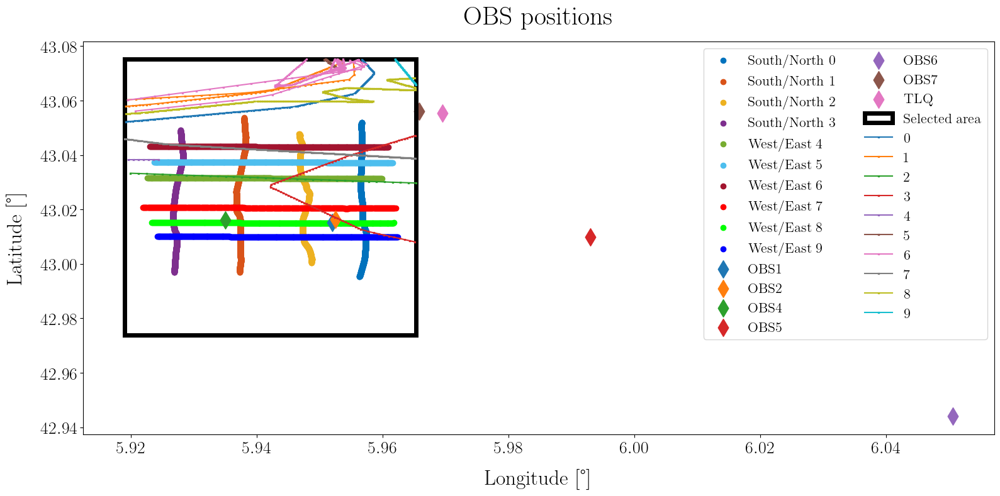

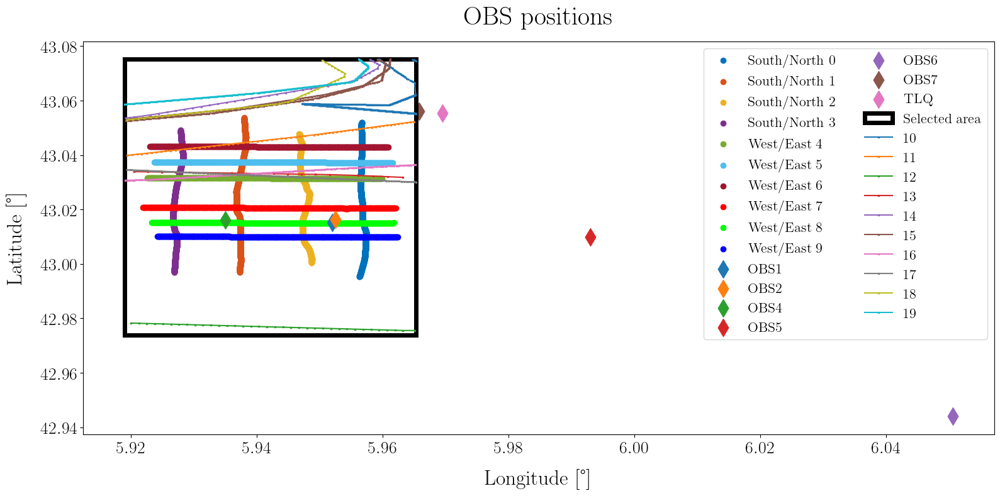

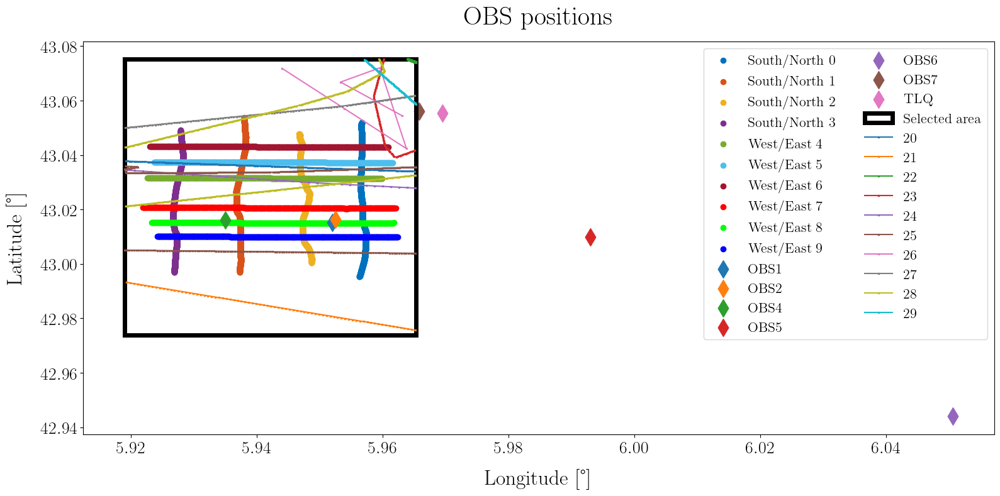

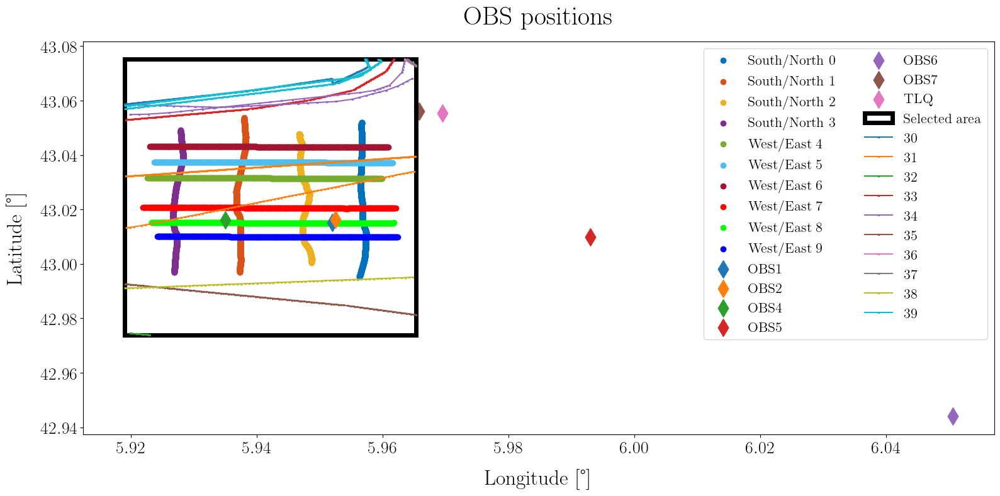

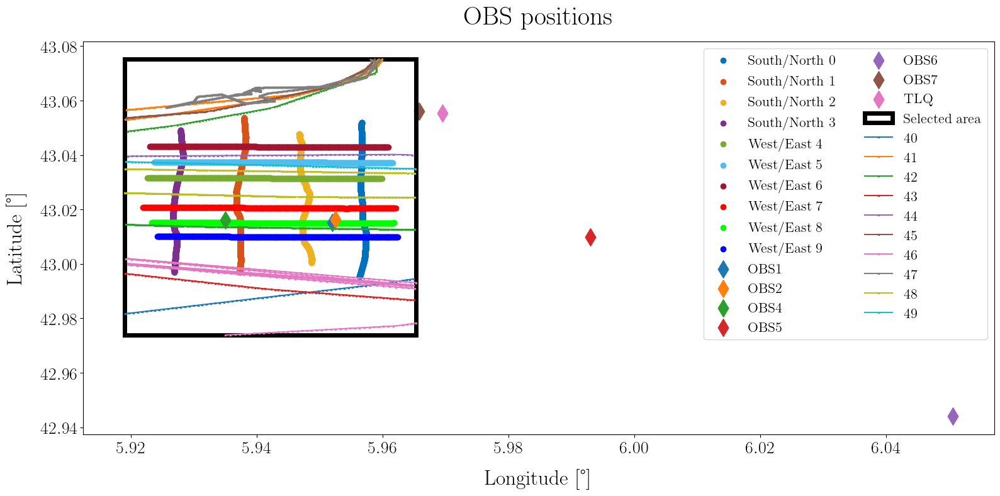

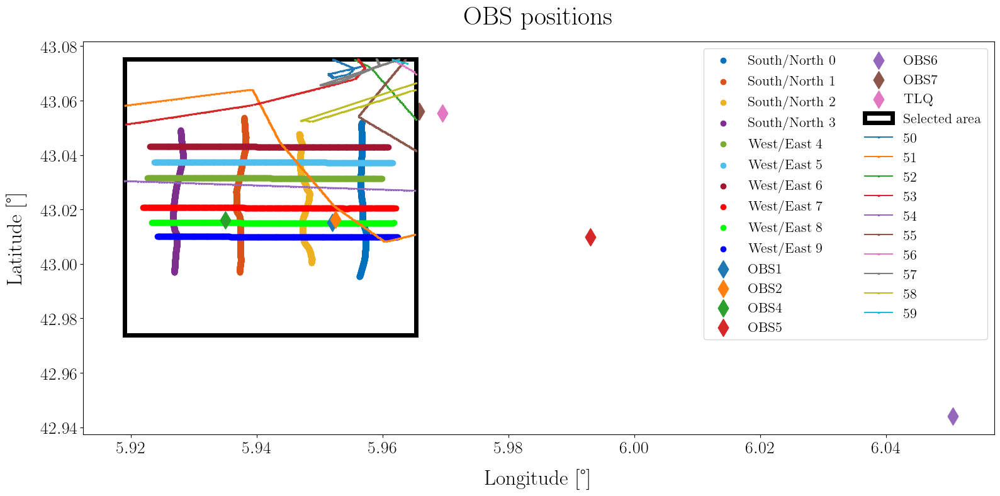

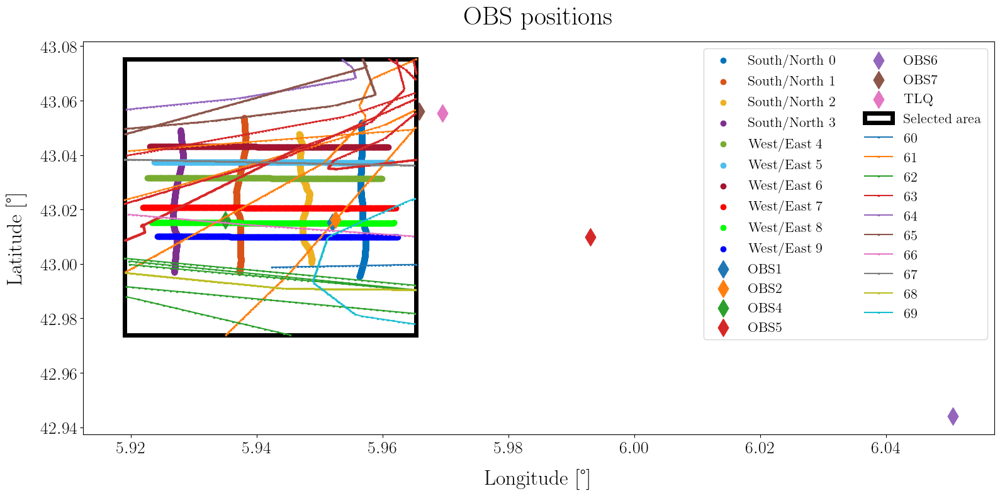

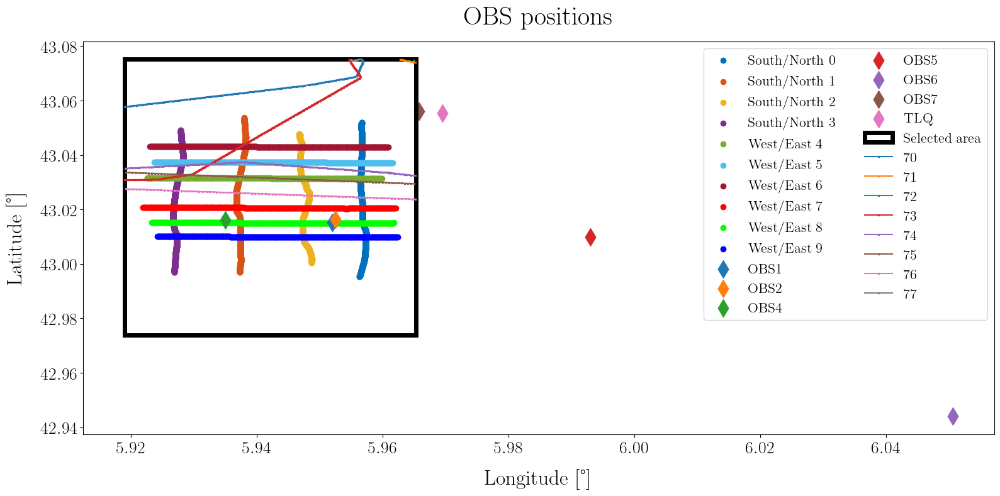

In [9]:
# Plot
# Illustrate on map by batches of 10
idx_mmsi_min = 0
mmsi_batch_size = 10
while idx_mmsi_min < ds_ais_in_area.sizes["mmsi"]:
    ds_ais_in_area_batch = ds_ais_in_area.isel(mmsi=slice(idx_mmsi_min, idx_mmsi_min+mmsi_batch_size))
    idx_mmsi_min += mmsi_batch_size

    fig, ax = plot_portion_tir_pos(portion_tree=portion)
    ax.add_patch(
        Rectangle(
            (lon_min, lat_min),
            lon_max - lon_min,
            lat_max - lat_min,
            fc="none",
            ec="k",
            lw=5,
            label="Selected area",
        )
    )

    for m in ds_ais_in_area_batch.mmsi.values:
        # print(m)
        pos_mmsi = ds_ais_in_area_batch.sel(mmsi=m)
        plt.plot(pos_mmsi.ais_lon, pos_mmsi.ais_lat, "-x", markersize=2, label=m)

    ax.legend()
    legend = ax.get_legend()

    if legend is not None:
        handles = legend.legend_handles
        labels = [text.get_text() for text in legend.get_texts()]

        legend.remove()

        ax.legend(
            handles,
            labels,
            loc="upper right",
            fontsize=16,
            ncols=2,
        )


Il y a bon nombre de trajectoires qui semblent exploitables. 

On peut sélectionner quelques trajectoires particulièrement intéressantes : 

* MMSI = 3 : trajectoire coudée, changement de cap au milieu de la grille 
* MMSI = 13, 17 : trajectoires zonales qui coïncident avec la section OE 4
* MMSi = 31 : diagonale NE -> SO 
* MMSI = 51 : diagonale NO -> SE
* MMSI = 61 : diagonale NE -> SO, plusieurs passages du même navire 

In [10]:
mmsi_selection = [3, 13, 17, 31, 51, 61]
ds_ais_selection = ds_ais_in_area.sel(mmsi=mmsi_selection)
ds_ais_selection

<xarray.Dataset> Size: 1MB
Dimensions:       (mmsi: 6, ais_datetime: 13204)
Coordinates:
  * mmsi          (mmsi) int64 48B 3 13 17 31 51 61
  * ais_datetime  (ais_datetime) datetime64[ns] 106kB 2026-02-24T03:27:00 ......
Data variables:
    ais_lon       (mmsi, ais_datetime) float64 634kB nan nan nan ... nan nan nan
    ais_lat       (mmsi, ais_datetime) float64 634kB nan nan nan ... nan nan nan
Attributes:
    description:              Positions AIS interpolées
    interpolation_time_step:  10s
    campagne:                 ACOUPLANE
    geodesic_frame:           WGS84

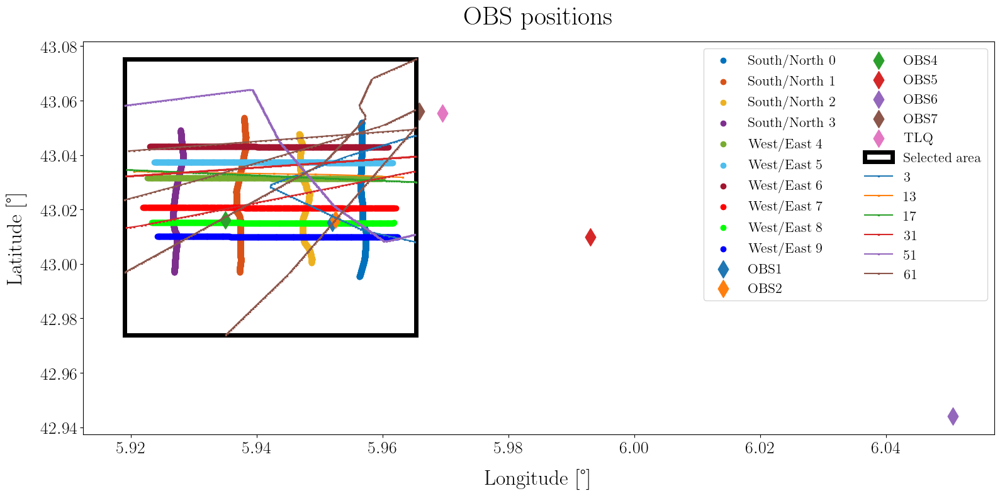

In [11]:
# Plot

fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (lon_min, lat_min),
        lon_max - lon_min,
        lat_max - lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)

for m in ds_ais_selection.mmsi.values:
    pos_mmsi = ds_ais_selection.sel(mmsi=m)
    plt.plot(pos_mmsi.ais_lon, pos_mmsi.ais_lat, "-x", markersize=2, label=m)

ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

In [12]:
# Cut into distinct events
event_sections = []
for m in ds_ais_selection.mmsi.values:
    pos_mmsi = ds_ais_selection.sel(mmsi=m)
    # print(pos_mmsi)
    # fig, axs = plt.subplots(2, 1, figsize=(16, 8))
    # pos_mmsi.ais_lon.plot(ax=axs[0])
    # pos_mmsi.ais_lat.plot(ax=axs[1])
    # plt.show()

    nan_indicator = np.isnan(pos_mmsi.ais_lon * pos_mmsi.ais_lat)
    edge_indicator = nan_indicator.astype(int)
    rising_edge = np.diff(edge_indicator.values, append=edge_indicator.values[-1]) == 1
    rising_edge_dt = pos_mmsi.ais_datetime.values[rising_edge]
    falling_edge = np.diff(edge_indicator.values, append=edge_indicator.values[-1]) == -1
    falling_edge_dt = pos_mmsi.ais_datetime.values[np.roll(falling_edge, +1)]       # Roll to avoid taking previosu point which is still a nan (diff = a[i+1] - a[i])

    n_section_for_current_mmsi = max(rising_edge_dt.size, falling_edge_dt.size)

    for isec in range(n_section_for_current_mmsi):
        pos_sec = pos_mmsi.sel(
            ais_datetime=slice(falling_edge_dt[isec], rising_edge_dt[isec])
        )
        event_sections.append(pos_sec)

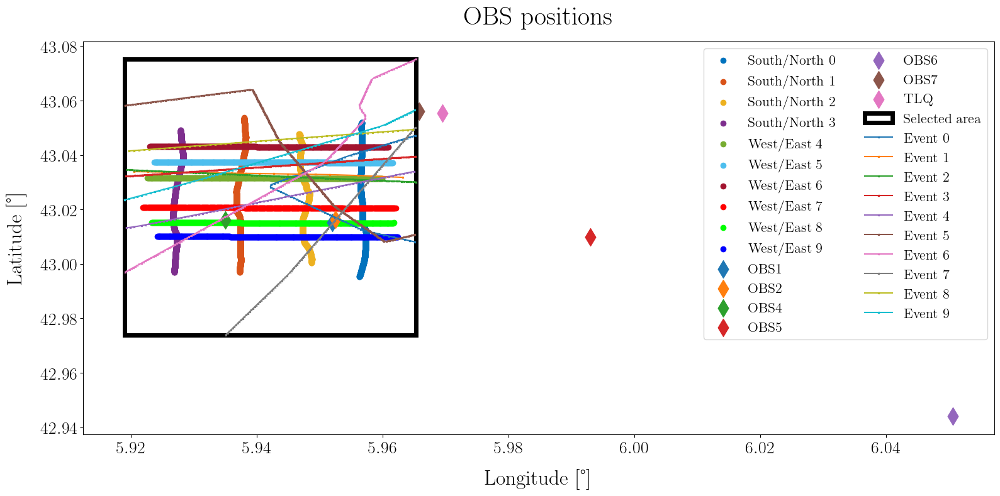

In [13]:
# Plot to check every thing is ok
fig, ax = plot_portion_tir_pos(portion_tree=portion)
ax.add_patch(
    Rectangle(
        (lon_min, lat_min),
        lon_max - lon_min,
        lat_max - lat_min,
        fc="none",
        ec="k",
        lw=5,
        label="Selected area",
    )
)

for isec, pos_sec in enumerate(event_sections):
    plt.plot(pos_sec.ais_lon, pos_sec.ais_lat, "-x", markersize=2, label=f"Event {isec}")

# for m in ds_ais_selection.mmsi.values:
#     pos_mmsi = ds_ais_selection.sel(mmsi=m)
#     plt.plot(pos_mmsi.ais_lon, pos_mmsi.ais_lat, "-x", markersize=2, label=m)

ax.legend()
legend = ax.get_legend()

if legend is not None:
    handles = legend.legend_handles
    labels = [text.get_text() for text in legend.get_texts()]

    legend.remove()

    ax.legend(
        handles,
        labels,
        loc="upper right",
        fontsize=16,
        ncols=2,
    )

In [14]:
portion_event = xr.DataTree()
event_ids = np.arange(len(event_sections))
portion_event["event_id"] = event_ids
portion_event.attrs = dict(
    box_lon_min=lon_min, box_lon_max=lon_max, box_lat_min=lat_min, box_lat_max=lat_max
)

for isec, pos_sec in enumerate(event_sections):

    ds_event_i = pos_sec.rename(
        dict(ais_datetime="datetime", ais_lon="lon", ais_lat="lat")
    )
    ds_event_i = ds_event_i.drop_vars("mmsi")
    ds_event_i["start_datetime"] = ds_event_i.datetime.min().values
    ds_event_i["stop_datetime"] = ds_event_i.datetime.max().values
    ds_event_i.attrs["event_id"] = isec
    ds_event_i.attrs["MMSI"] = pos_sec.mmsi.values

    path = f"position/event_{isec}"
    portion_event[path] = ds_event_i

In [15]:
portion_event

<xarray.DataTree>
Group: /
│   Dimensions:   (dim_0: 10)
│   Dimensions without coordinates: dim_0
│   Data variables:
│       event_id  (dim_0) int64 80B 0 1 2 3 4 5 6 7 8 9
│   Attributes:
│       box_lon_min:  5.919009015
│       box_lon_max:  5.965350184499999
│       box_lat_min:  42.973826338
│       box_lat_max:  43.07525886599999
└── Group: /position
    ├── Group: /position/event_0
    │       Dimensions:         (datetime: 95)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 760B 2026-02-24T14:40:50 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 760B 5.965 5.965 5.964 ... 5.964 5.965
    │           lat             (datetime) float64 760B 43.05 43.05 43.05 ... 43.01 43.01
    │           start_datetime  datetime64[ns] 8B 2026-02-24T14:40:50
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T14:56:30
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 0
    │           MMSI:                     3
    ├── Group: /position/event_1
    │       Dimensions:         (datetime: 19)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 152B 2026-02-24T16:14:20 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 152B 5.963 5.961 5.959 ... 5.923 5.92
    │           lat             (datetime) float64 152B 43.03 43.03 43.03 ... 43.03 43.03
    │           start_datetime  datetime64[ns] 8B 2026-02-24T16:14:20
    │           stop_datetime   datetime64[ns] 8B 2026-02-24T16:17:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 1
    │           MMSI:                     13
    ├── Group: /position/event_2
    │       Dimensions:         (datetime: 119)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 952B 2026-03-02T12:58:40 ... 20...
    │       Data variables:
    │           lon             (datetime) float64 952B 5.965 5.965 5.965 ... 5.92 5.919
    │           lat             (datetime) float64 952B 43.03 43.03 43.03 ... 43.03 43.03
    │           start_datetime  datetime64[ns] 8B 2026-03-02T12:58:40
    │           stop_datetime   datetime64[ns] 8B 2026-03-02T13:18:20
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 2
    │           MMSI:                     17
    ├── Group: /position/event_3
    │       Dimensions:         (datetime: 173)
    │       Coordinates:
    │         * datetime        (datetime) datetime64[ns] 1kB 2026-02-28T23:01:20 ... 202...
    │       Data variables:
    │           lon             (datetime) float64 1kB 5.965 5.965 5.965 ... 5.92 5.92 5.919
    │           lat             (datetime) float64 1kB 43.04 43.04 43.04 ... 43.03 43.03
    │           start_datetime  datetime64[ns] 8B 2026-02-28T23:01:20
    │           stop_datetime   datetime64[ns] 8B 2026-02-28T23:30:00
    │       Attributes:
    │           description:              Positions AIS interpolées
    │           interpolation_time_step:  10s
    │           campagne:                 ACOUPLANE
    │           geodesic_frame:           WGS84
    │           event_id:                 3
    │           MMSI:                     31
    ├── Group: /position/event_4
    │       Dimensions:         (datetime: 80)
    │       Coordinates:
    │         * datetime        (datetime

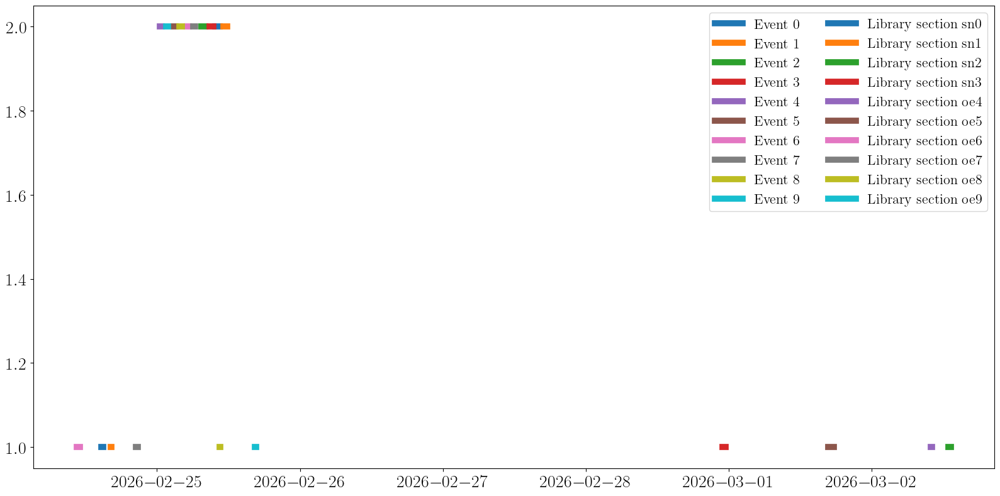

In [17]:
# Common period
plt.figure()

for name, node in portion_event.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.datetime,
        np.ones(ds_position_section.datetime.size),
        label=f"Event {name.split('_')[1]}",
        linewidth=7,
    )

for name, node in portion.position.children.items():
    ds_position_section = node.to_dataset()
    plt.plot(
        ds_position_section.src_datetime,
        2 * np.ones(ds_position_section.src_datetime.size),
        label=f"Library section {name}",
        linewidth=7,
    )

plt.legend(ncol=2, loc="upper right", fontsize=16)

# Extraction signaux associés aux navires sélectionnés 

## Chargement des signaux 

In [10]:
ds_pressure = xr.open_dataset(ACOUPLANE_PRESSURE_NC_FPATH)
ds_pressure

<xarray.Dataset> Size: 800MB
Dimensions:         (time_obs1: 100014000, time_obs2: 100034000, obs_id: 2)
Coordinates:
  * obs_id          (obs_id) <U4 32B 'obs1' 'obs2'
Dimensions without coordinates: time_obs1, time_obs2
Data variables:
    pressure_obs1   (time_obs1) int32 400MB ...
    pressure_obs2   (time_obs2) int32 400MB ...
    start_datetime  (obs_id) datetime64[ns] 16B ...
Attributes:
    description:  Données de pression (voie hydro 3)
    campagne:     ACOUPLANE
    fs:           2000
    fullscale:    4.52

## Conversion des données et calcul vecteurs temps pour slicing 

Les données stockées sont les données raw, il faut donc les convertir et fabriquer le vecteur de temps.

In [ ]:
# Build a vector of datetime for each OBS signal
obs_datetimes = build_obs_datetime_vector(ds_pressure=ds_pressure)

## Extraction et stockage 

In [ ]:
for name, node in portion_event.position.children.items():
    ds_position_section = node.to_dataset()
    # ds_pressure_section_sn1 = extract_and_plot_pressure_section(
    #     ds_position_section.start_datetime,
    #     ds_position_section.stop_datetime,
    #     ds_pressure,
    #     obs_datetimes,
    #     single_fig=False,
    # )

    ds_pressure_section = extract_pressure_section(
        ds_position_section.start_datetime,
        ds_position_section.stop_datetime,
        ds_pressure,
        obs_datetimes,
    )
    ds_pressure_section = convert_raw_pressure_to_physical_units(
        ds_pressure=ds_pressure_section
    )

    # Store in event portion
    path = f"pressure/event_{ds_position_section.event_id}"
    portion_event[path] = ds_pressure_section

## Visualisation des signaux 

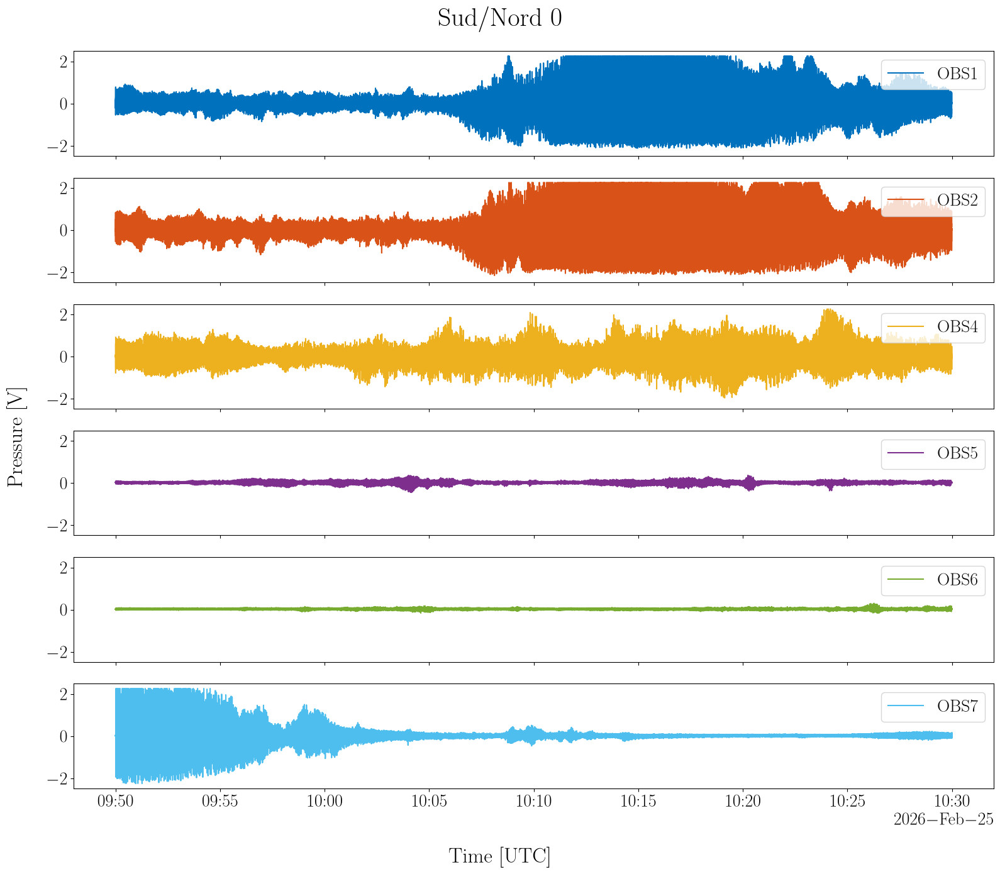

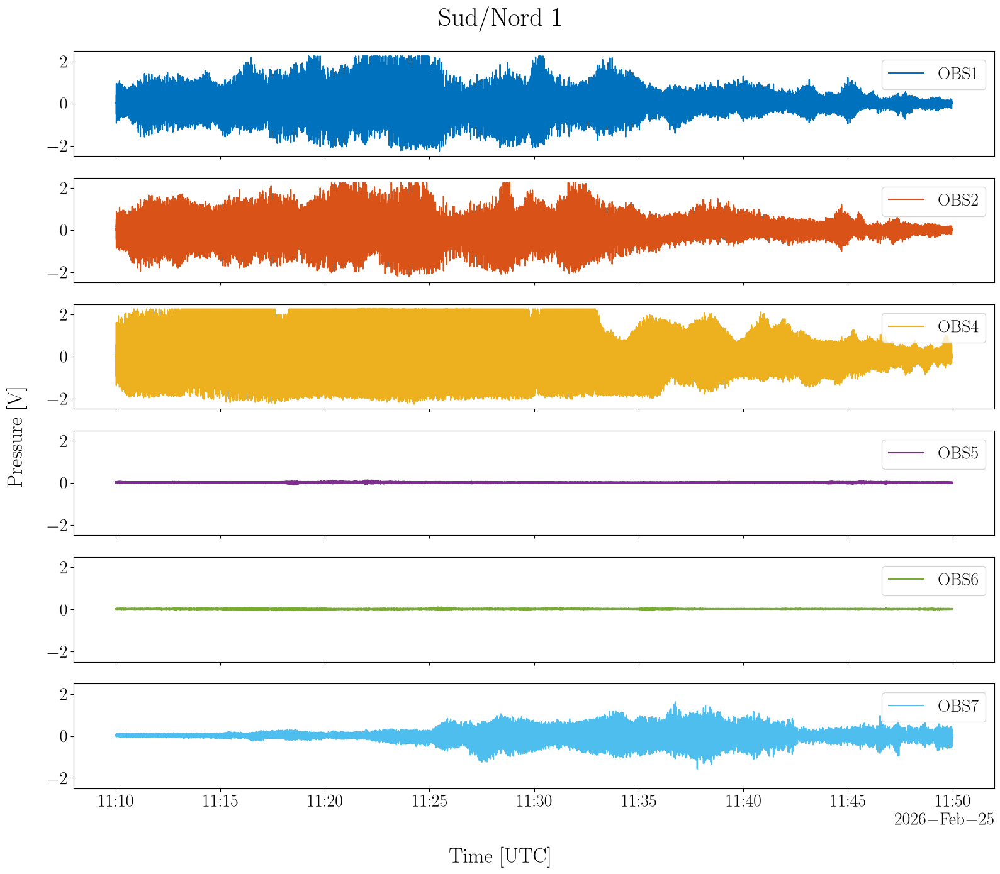

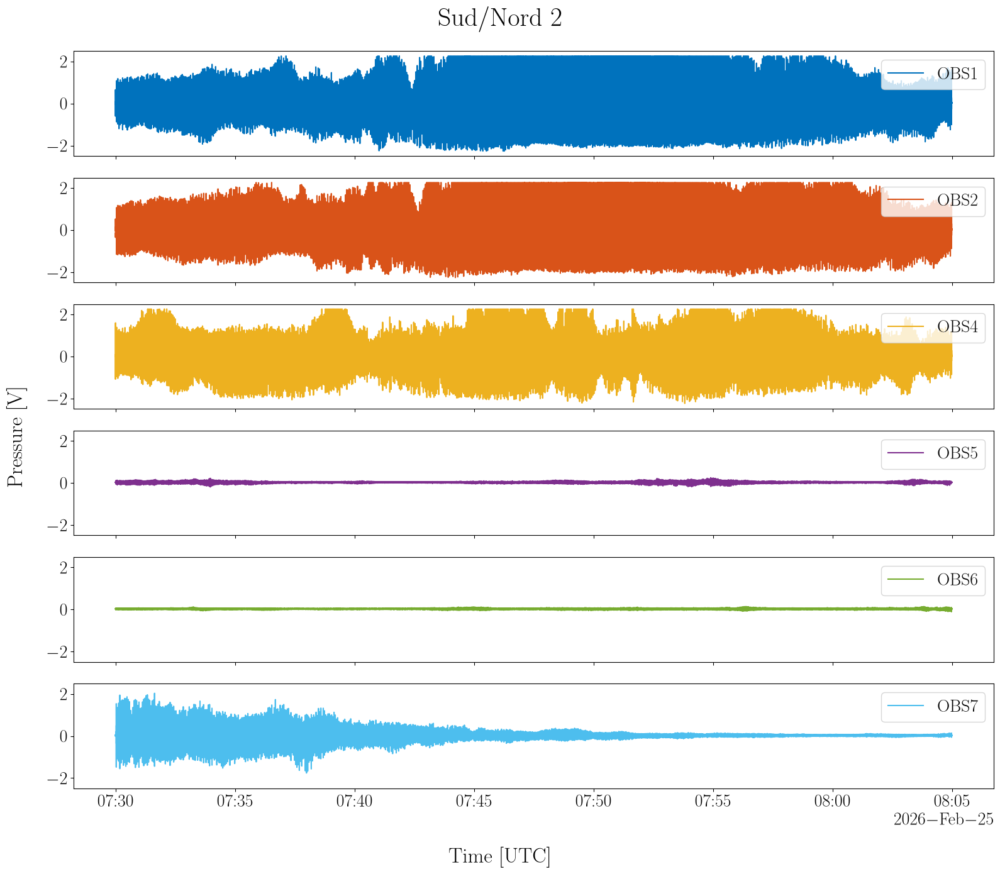

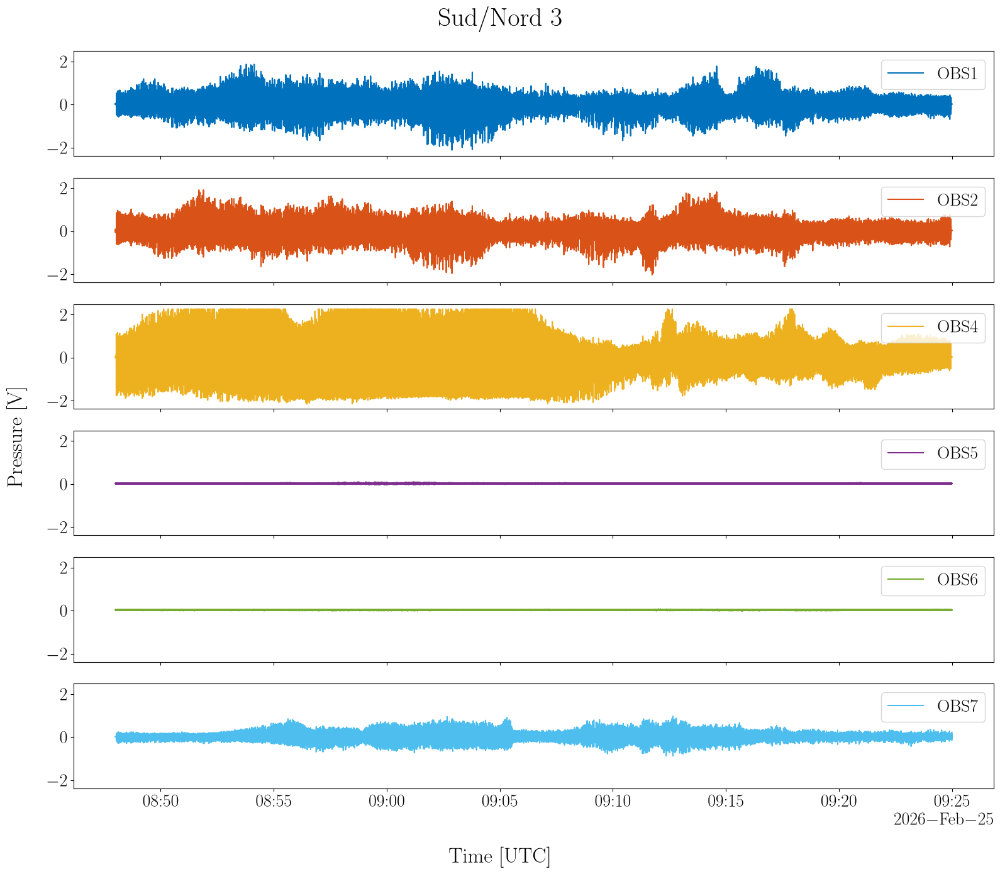

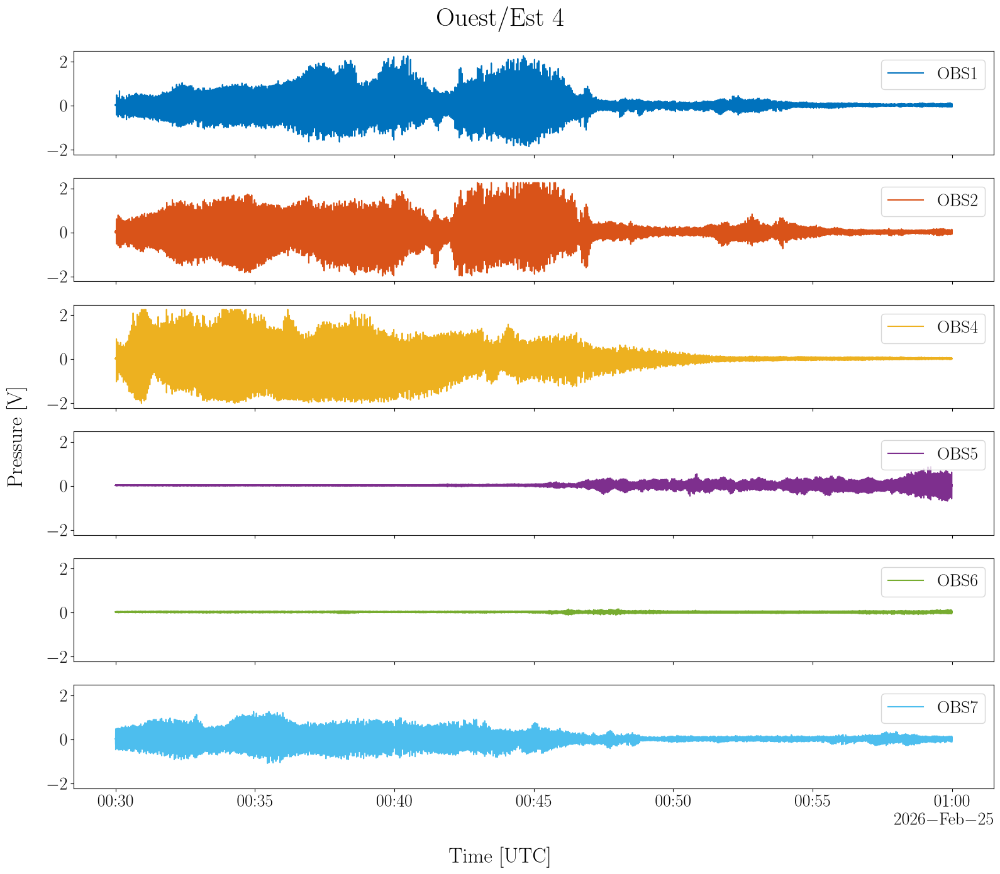

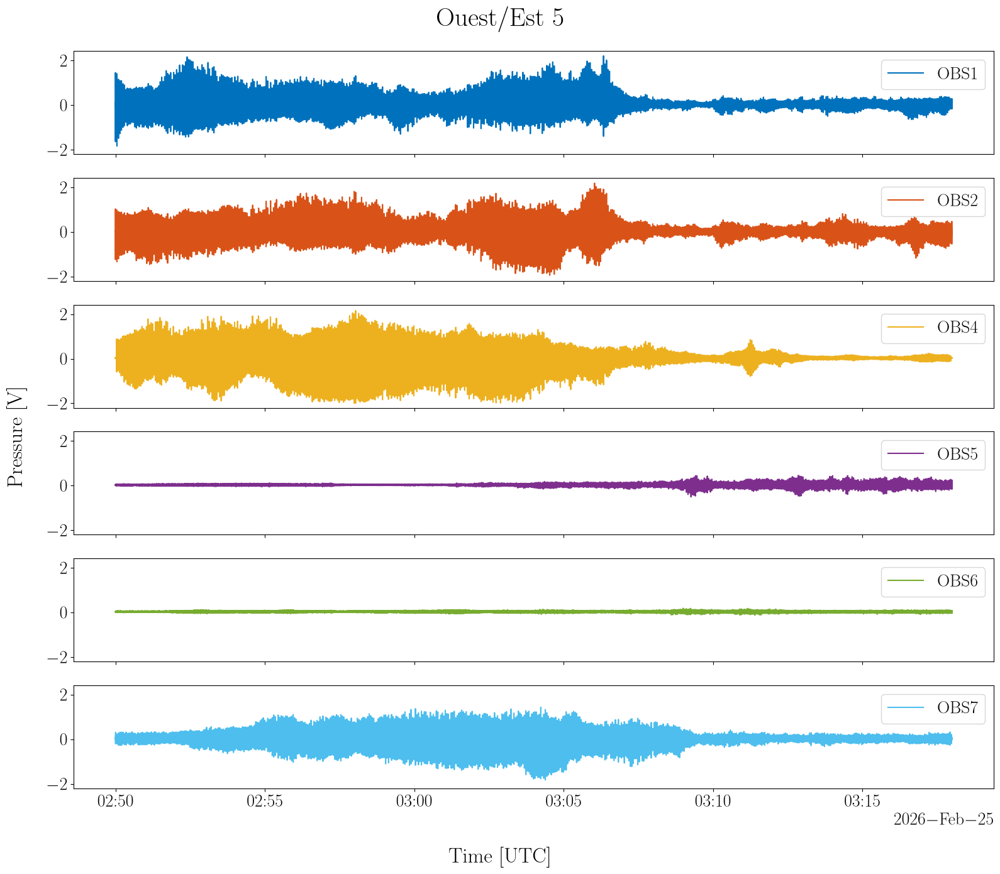

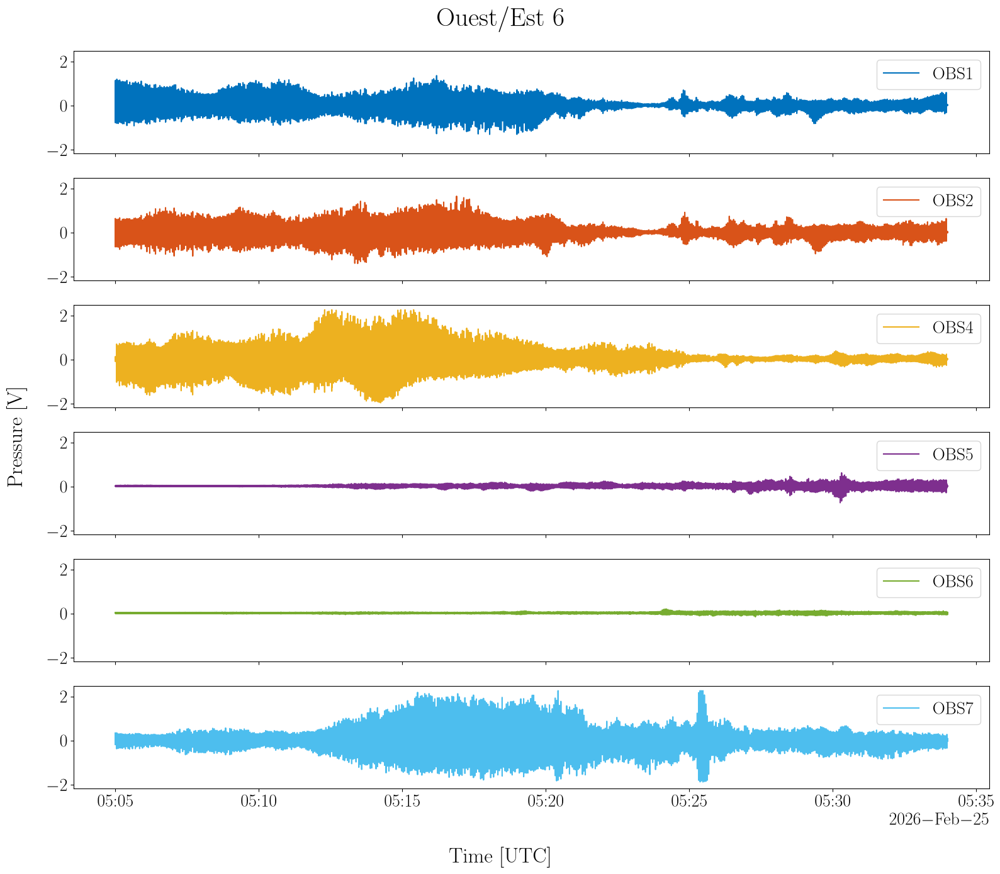

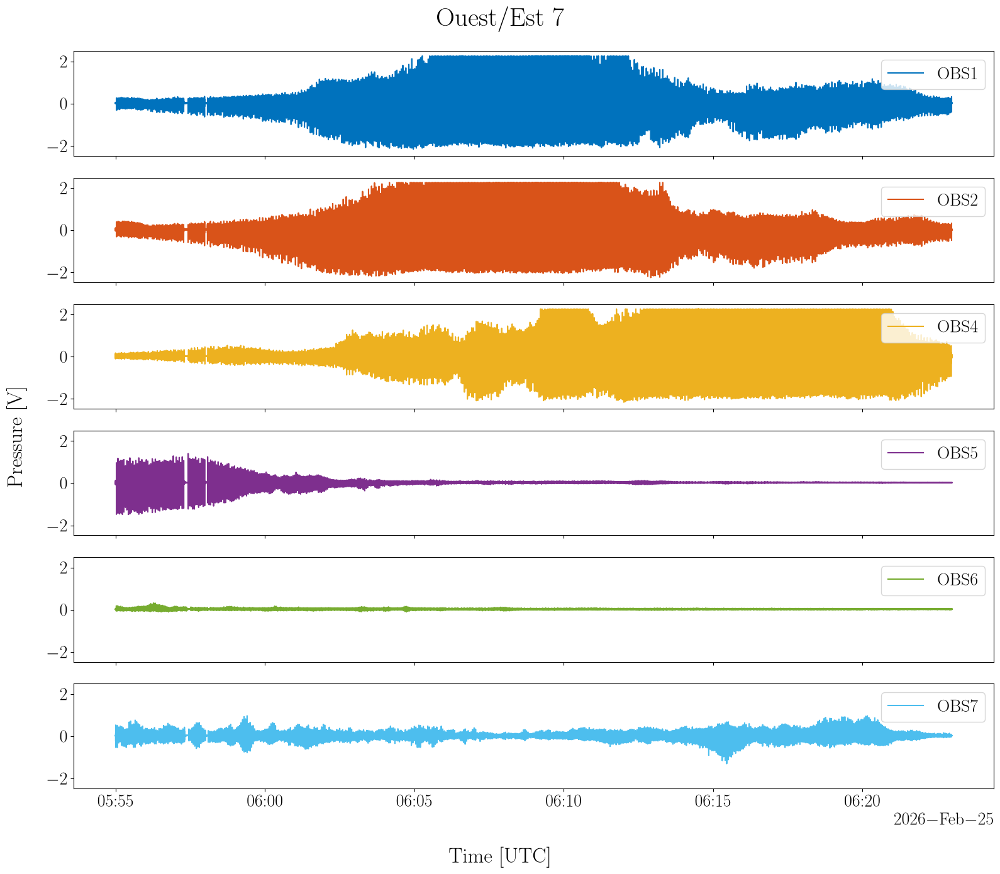

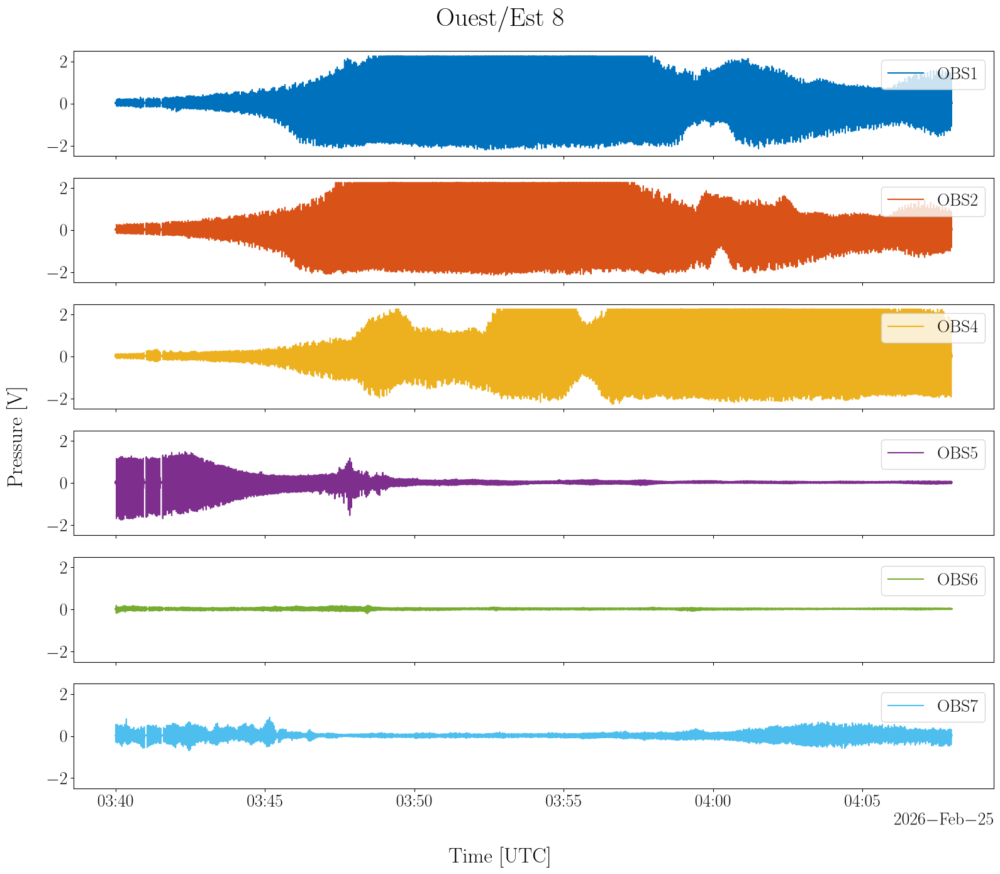

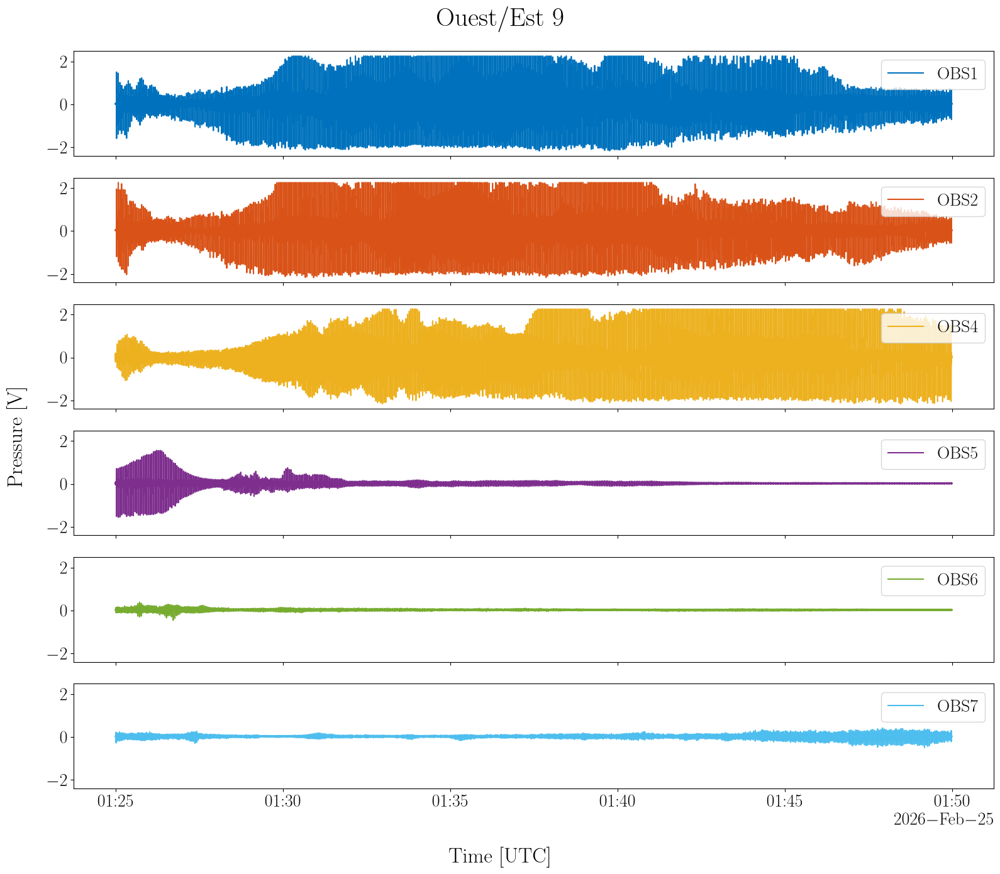

In [6]:
# Plot
single_fig = False
for name, node in portion_event.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
    fig.suptitle(f"Event {ds_pressure_section.event_id}")
    plt.show()

## Spectrogrames 

**Remarque** : l'amplitude des cannons décroit avec le temps avant de revenir à l'amplitude de départ. Ce comportement nominal des cannons à air comprimé se traduit par une modulation d'amplitude des tirs visibles sur les spectrogrames ci dessous.    

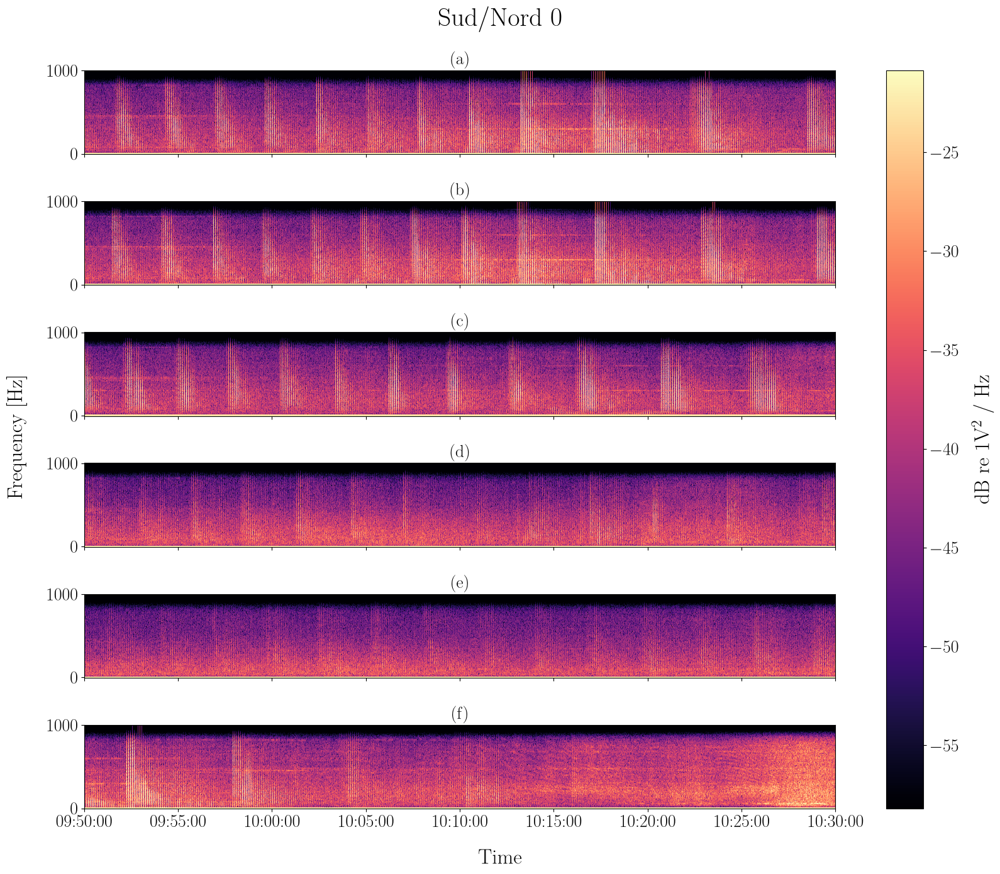

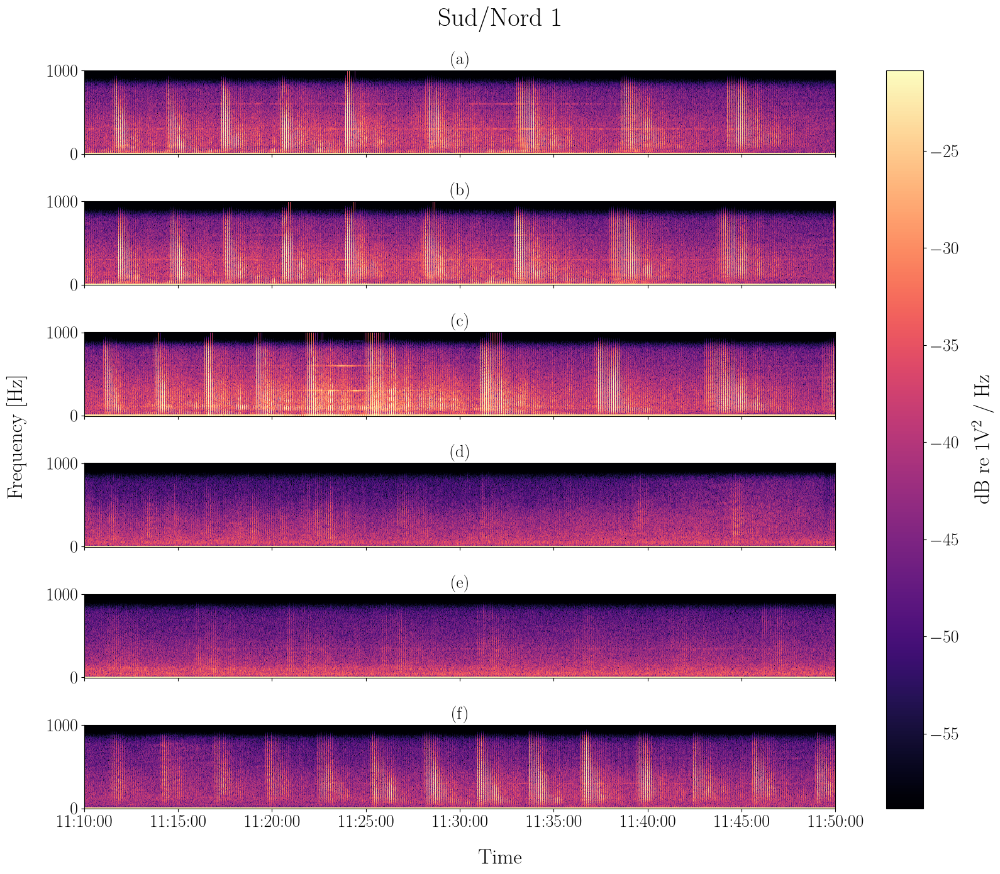

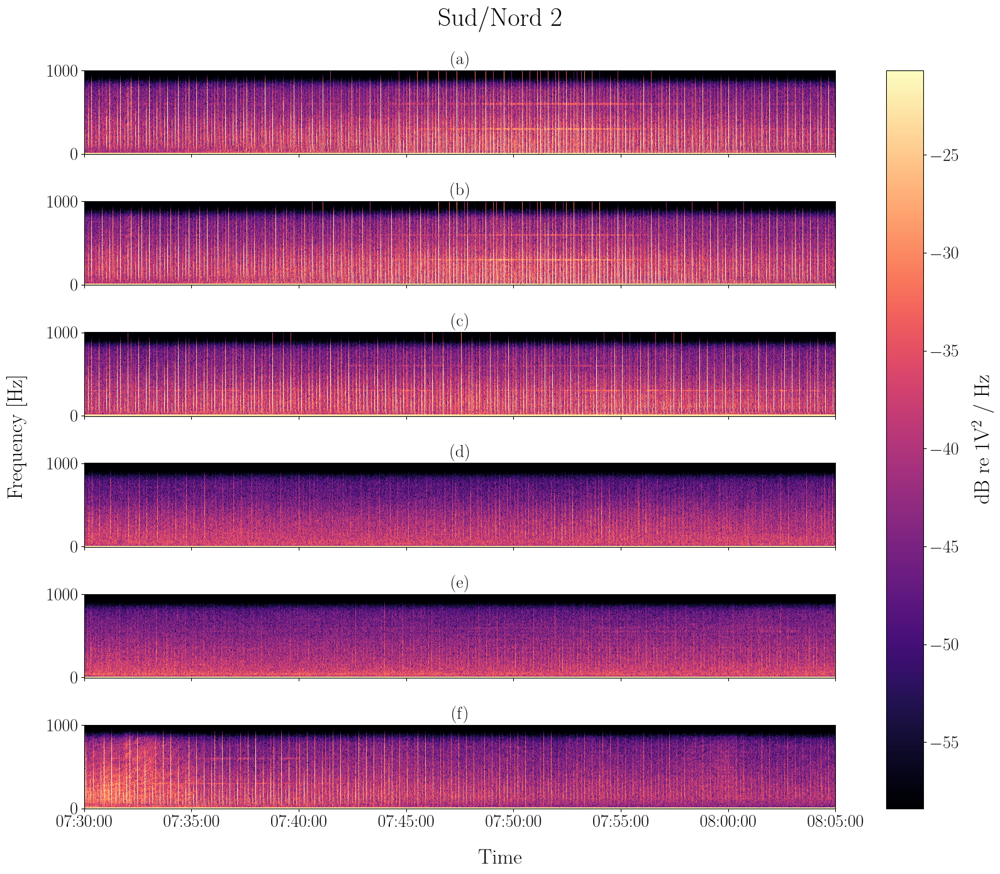

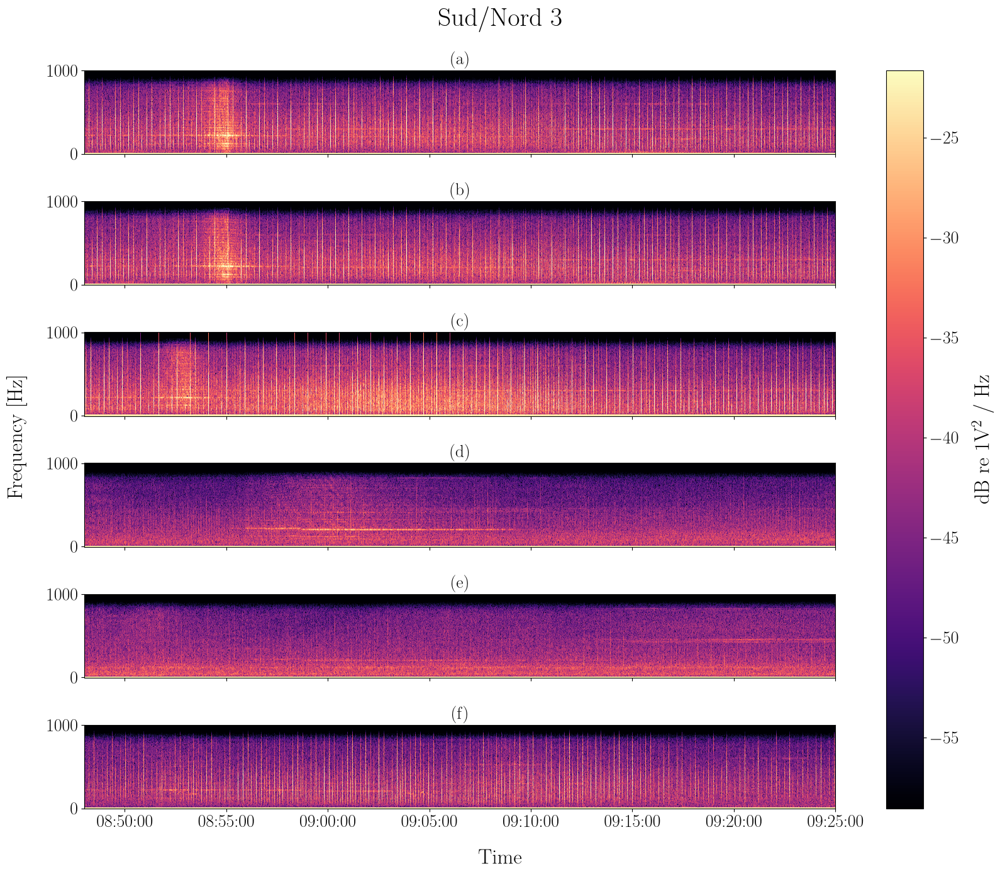

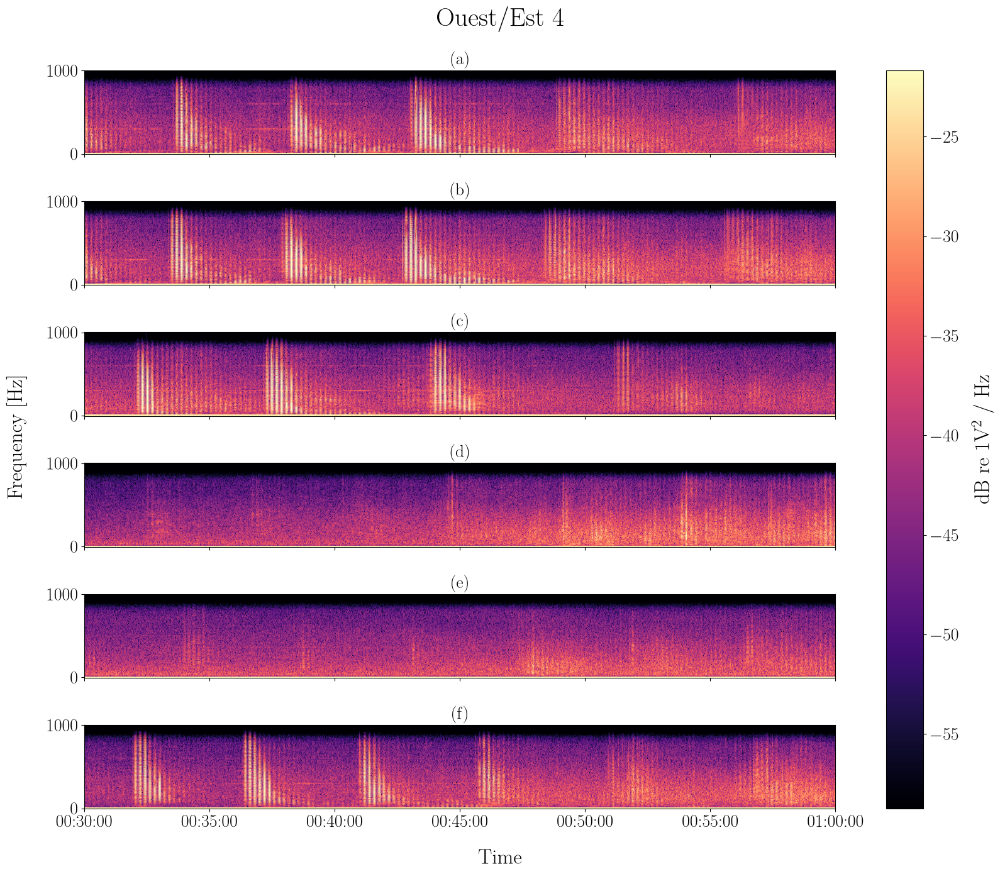

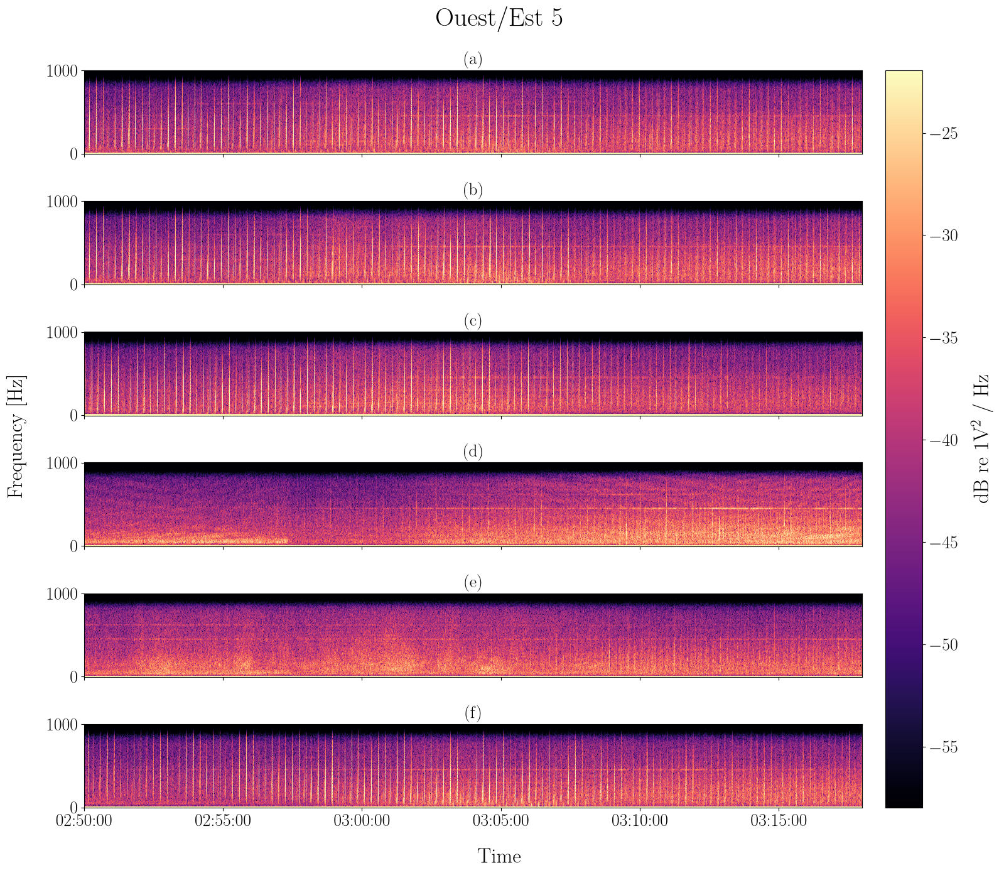

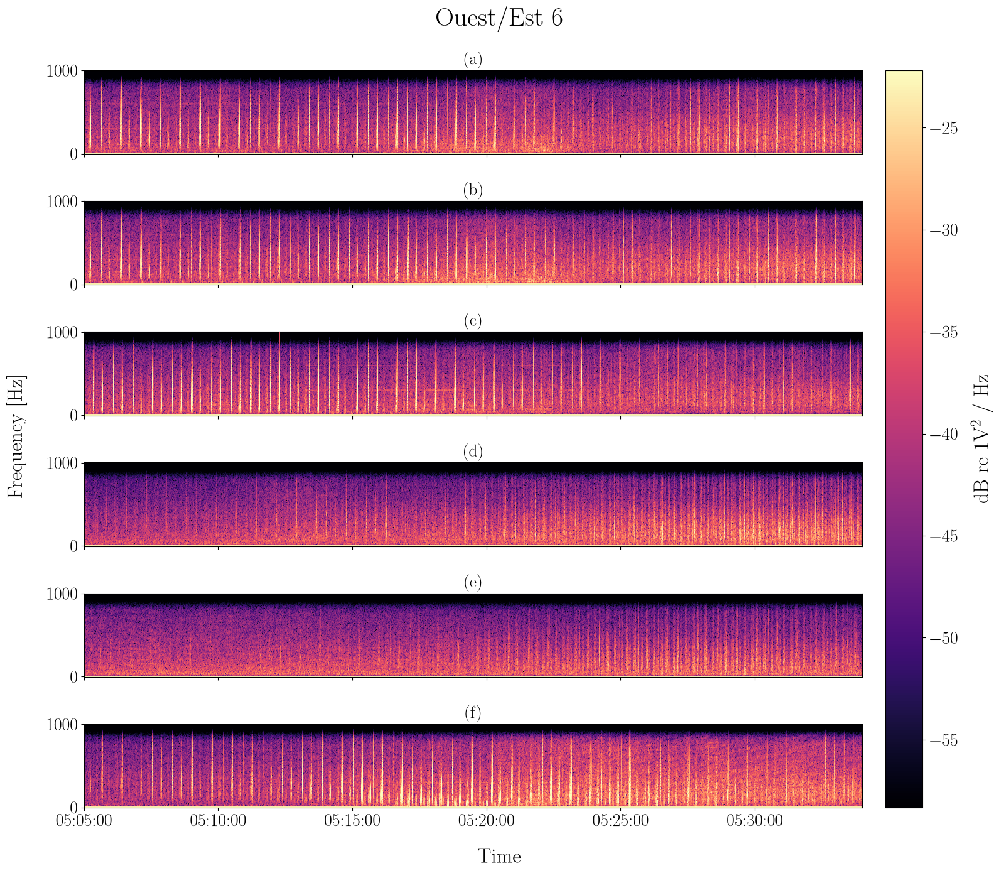

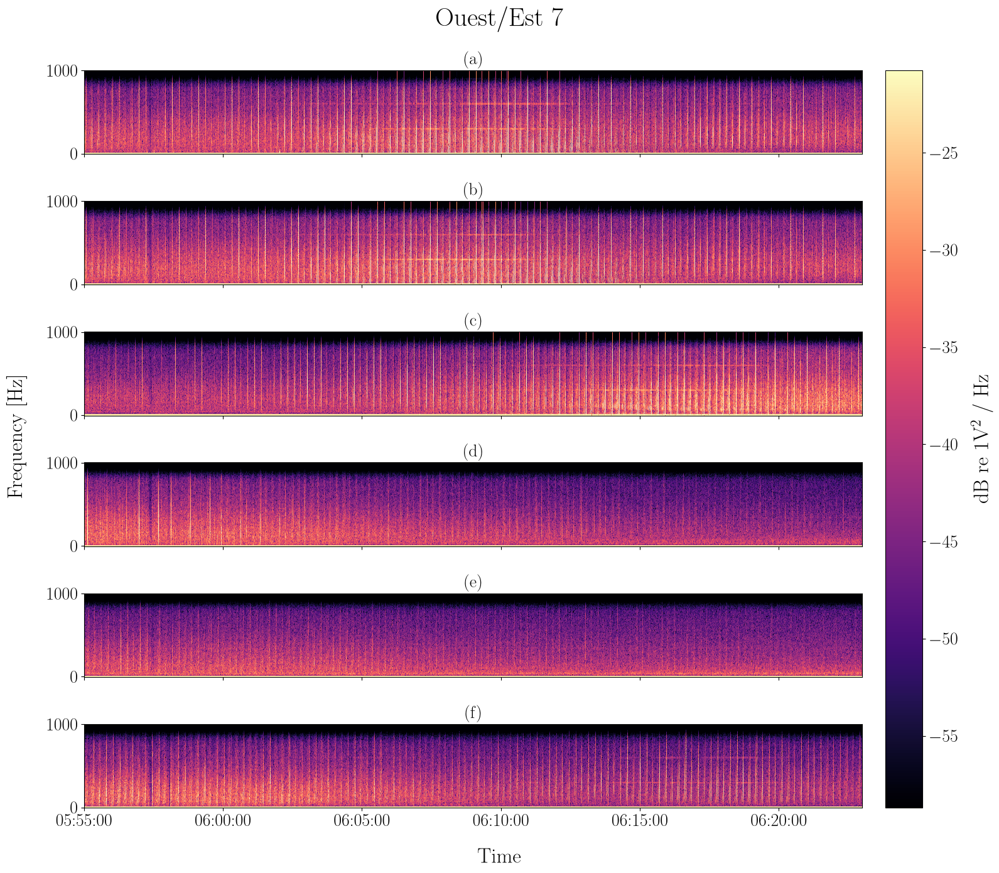

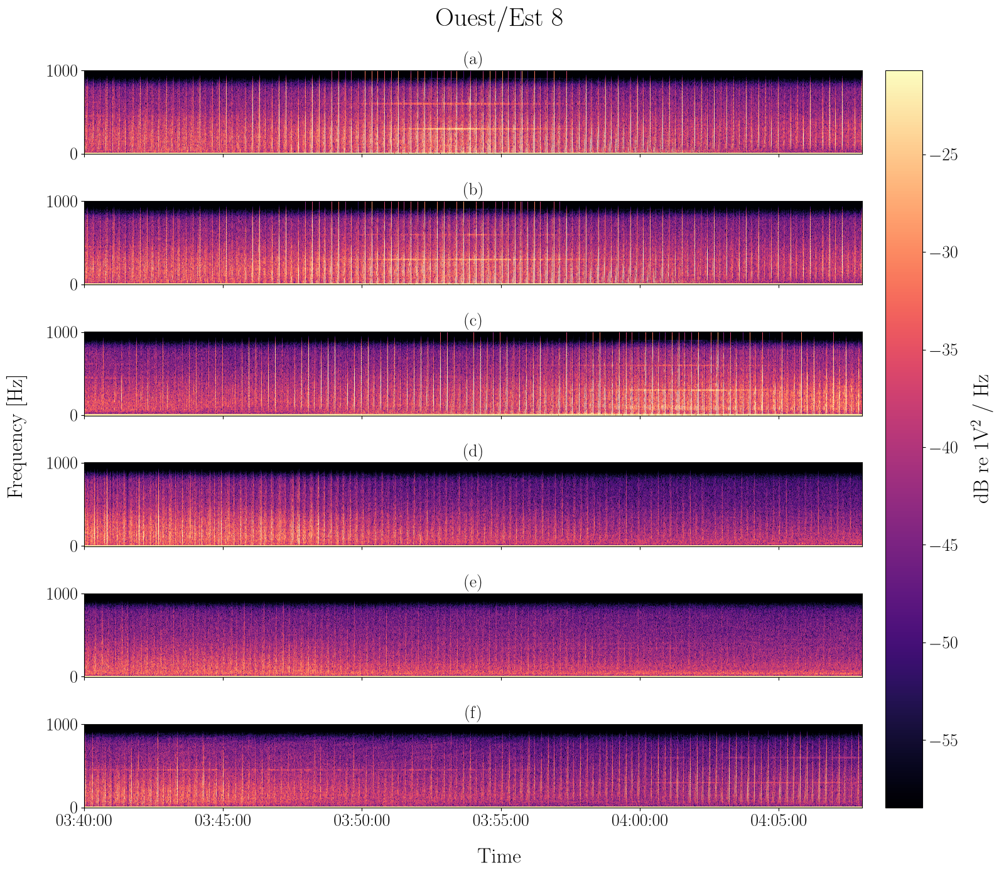

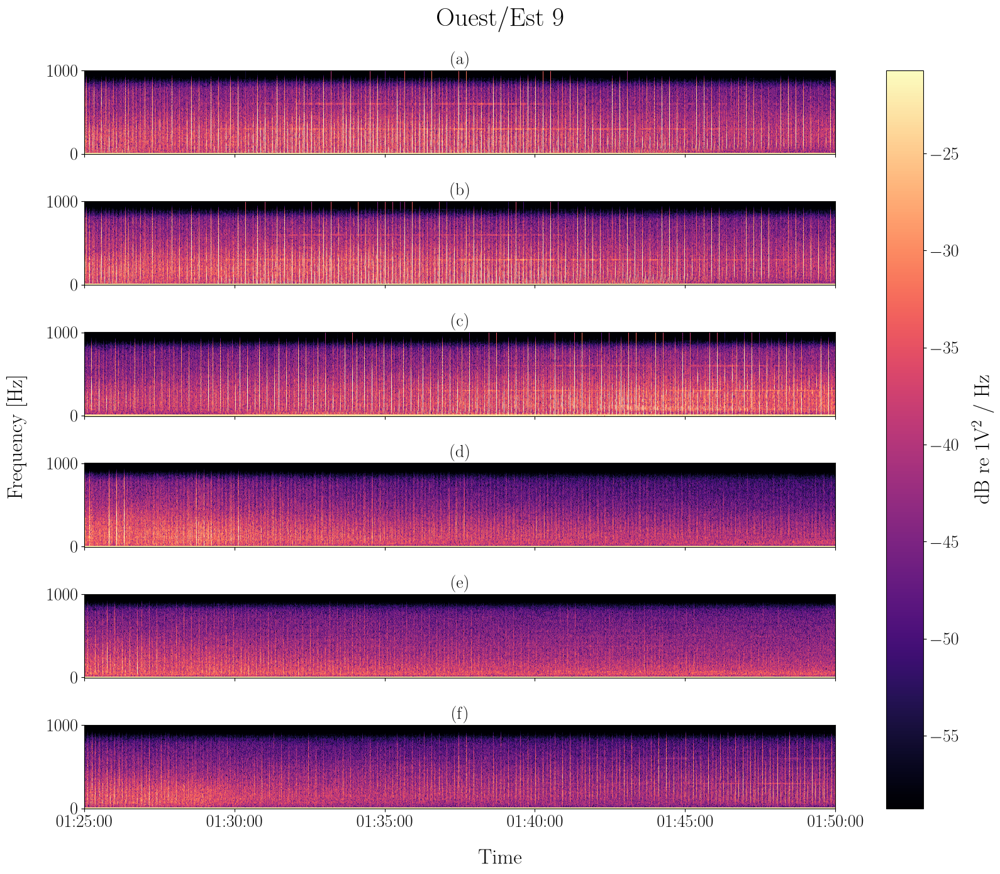

In [7]:
# Plot
for name, node in portion_event.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**8, noverlap=2**7, cmap="magma")
    fig.suptitle(f"Event {ds_pressure_section.event_id}")
    plt.show()

# Sauvergarde de la portion event 

In [19]:
# Save as netcdf
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}_event.nc"
portion_event.attrs["portion_filepath"] = fpath
portion_event.to_netcdf(fpath)